# Kết quả cuối E0–E4 — Phan Trọng Hoàn

E1/E2/E3 và E4 đủ 300 bước. Notebook này đọc evidence thật đã lưu, không tải model hoặc train; chạy được CPU tại repo. Không coi các cell chưa thực thi trong notebook này là lượt suy luận mới. Pipeline huấn luyện/suy luận: src/run.py, src/train.py, src/inference.py; chỉ chạy model trên Colab GPU. Nguồn Colab do sinh viên cung cấp: extended300_results (1).zip, extended300_figures.zip và notebook tải về (1)/(2), giữ riêng local. Xem REPORT.md để biết resume, mất backup E4 v1 và chạy lại v2, AMP scale khác và model_revision=null.

Sau khi Run all thành công, Save a copy in Drive và tải .ipynb để lưu output thật. Không sửa JSON evidence. Biểu đồ F1/CI95 nằm ngay trong output notebook, không sinh file phụ.


## 0. Môi trường và phạm vi
Chọn Colab CPU (Hardware accelerator: None), rồi Run all. Cell đầu chỉ clone source/evidence nếu chưa có workspace; không cài thư viện hoặc tải model/dataset. Chạy local từ thư mục gốc repo. Kết quả train đã có; các output mới là đọc artifact và vẽ hình bằng CPU.


In [11]:
from pathlib import Path
import json
import os
import sys
import importlib.util
import subprocess
import tempfile

ROOT = Path.cwd()
try:
    in_colab = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    in_colab = False
if in_colab:
    # Fresh source/evidence avoids accidentally reading an old training workspace.
    # No dataset, model or checkpoint downloads.
    ROOT = Path(tempfile.mkdtemp(prefix='day10_submission_', dir='/content'))
    subprocess.run(['git', 'clone', '--depth', '1',
        'https://github.com/naoh-pt/K4-Track-4-Day10-VisionLanguageModel.git', str(ROOT)], check=True)
    os.chdir(ROOT)
    sys.path.insert(0, str(ROOT))
assert (ROOT / 'report/evidence/e3.json').exists(), 'Local: mở từ thư mục gốc repo.'
print('Source:', ROOT)
print('Commit:', subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'], text=True).strip())


Source: /content/day10_submission_9cq_t4z2
Commit: 9949d0e


## 1. Dữ liệu và split
Không tải lại dữ liệu để xem báo cáo. Meta dưới do prepare_data.py gốc sinh, version d10-21e4070301.


In [12]:
meta = json.loads((ROOT / 'report/analysis/dataset_meta.json').read_text(encoding='utf-8'))
assert meta['dataset_version'] == 'd10-21e4070301'
print(meta)


{'dataset_version': 'd10-21e4070301', 'seed': 'day10', 'salt': 0, 'classes': ['pothole', 'crack', 'manhole'], 'counts': {'train': {'images': 1422, 'boxes': {'pothole': 1074, 'crack': 1750, 'manhole': 691}}, 'val': {'images': 276, 'boxes': {'pothole': 66, 'crack': 470, 'manhole': 103}}, 'test': {'images': 311, 'boxes': {'pothole': 121, 'crack': 299, 'manhole': 163}}}, 'groups': {'vlc-2025-02-19-13': 'train', 'vlc-2025-02-19-15': 'train', 'phone-20250216': 'train', 'num-1': 'train', 'phone-20250219': 'train', 'num-0': 'train', 'vlc-2025-03-16-15': 'train', 'vlc-2025-02-19-14': 'train', 'vlc-2025-02-26-20': 'train', 'vlc-2025-02-18-18': 'val', 'num-4': 'test', 'vlc-2025-02-19-17': 'test', 'vlc-2025-02-18-17': 'train', 'vlc-2025-02-18-23': 'test', 'phone-20250223': 'train', 'num-3': 'train', 'vlc-2025-02-19-16': 'val', 'num-2': 'train'}}


## 2. Kiến trúc thực đo
Số tham số được đếm từ base model thật trên Colab trước khi gắn LoRA; không nạp model ở cell này.


In [13]:
print(json.loads((ROOT / 'report/analysis/architecture.json').read_text()))


{'groups': {'visual_backbone': 306242560, 'merger': 27271680, 'deepstack_mergers': 81833472, 'language_model': 4022468096, 'lm_head': 0, 'other': 0}, 'total_unique_parameters': 4437815808, 'projector_total': 109105152, 'visual_total': 415347712, 'method': 'named_parameters removes shared duplicates; Params4bit uses original quant_state.shape', 'model_revision': None}


## 3. E0–E3: evidence test
JSON gốc scorer, đủ 311 ảnh. E1/E2/E3 đủ 300 optimizer steps. Không tái sinh output từ model.


In [14]:
from pathlib import Path
import json
ROOT = Path.cwd()
assert (ROOT / 'report/evidence/e3.json').exists(), 'Chạy từ thư mục gốc repo.'
names = ['e0', 'e1', 'e2', 'e3', 'e4_data_size_0.1', 'e4_data_size_1.0']
evidence = {name: json.loads((ROOT / 'report/evidence' / f'{name}.json').read_text(encoding='utf-8')) for name in names}
for name, d in evidence.items():
    assert d['n_images'] == 311 and d['missing_predictions'] == 0
    print(name, 'F1=', d['micro']['f1'], 'CI95=', d['f1_ci95'], 'valid=', d['parse_valid_rate'])


e0 F1= 0.05090137857900318 CI95= [0.03289473684210526, 0.07127882599580714] valid= 0.40192926045016075
e1 F1= 0.2603978300180832 CI95= [0.2247992863514719, 0.29955156950672646] valid= 1.0
e2 F1= 0.3293903548680619 CI95= [0.2911737943585077, 0.3719165085388994] valid= 0.9967845659163987
e3 F1= 0.4335154826958106 CI95= [0.39512619669277627, 0.47591522157996147] valid= 0.9935691318327974
e4_data_size_0.1 F1= 0.3027950310559006 CI95= [0.26899696048632216, 0.33725490196078434] valid= 1.0
e4_data_size_1.0 F1= 0.4335154826958106 CI95= [0.39512619669277627, 0.47591522157996147] valid= 0.9935691318327974


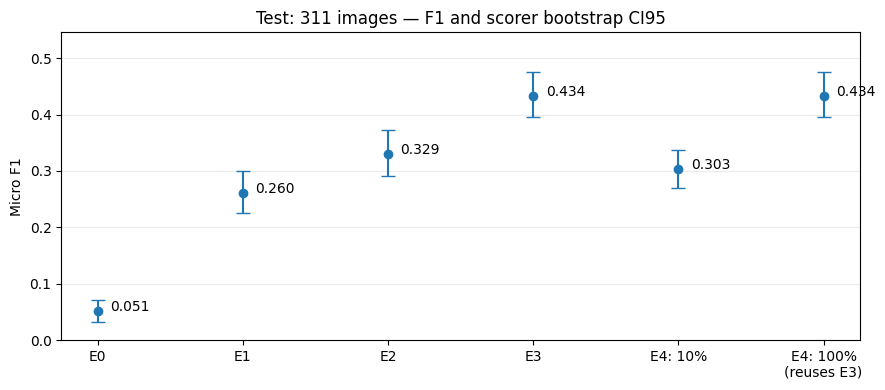

In [15]:
from src.results import plot_f1_ci
import matplotlib.pyplot as plt
fig = plot_f1_ci(ROOT / 'report/evidence')
plt.show()


## 4. Chọn nền E4 bằng val
Chốt E3 trước test E4; không chọn bằng test. Run10% khởi tạo từ model gốc.


In [16]:
from src.results import choose_by_val
base = choose_by_val(ROOT / 'report/validation')
assert base == 'e3'
for name in ('e3', 'e4_data_size_0.1', 'e4_data_size_1.0'):
    assert evidence[name]['meta']['actual_steps'] == 300
delta = evidence['e4_data_size_1.0']['micro']['f1'] - evidence['e4_data_size_0.1']['micro']['f1']
print('F1 giảm khi dùng10%:', delta)
print(json.loads((ROOT / 'report/analysis/architecture.json').read_text()))


Chọn đối chứng bằng F1 val: [(0.20724515585509692, 'e1'), (0.30017152658662094, 'e2'), (0.3621399176954732, 'e3')] => e3
F1 giảm khi dùng10%: 0.13072045163990997
{'groups': {'visual_backbone': 306242560, 'merger': 27271680, 'deepstack_mergers': 81833472, 'language_model': 4022468096, 'lm_head': 0, 'other': 0}, 'total_unique_parameters': 4437815808, 'projector_total': 109105152, 'visual_total': 415347712, 'method': 'named_parameters removes shared duplicates; Params4bit uses original quant_state.shape', 'model_revision': None}


## 5. Bẫy tọa độ
Cùng prediction E3 300 bước, chấm norm1000 và cố ý chấm sai như pixel; JSON hợp lệ không bảo đảm box đúng.


In [17]:
coord = json.loads((ROOT / 'report/analysis/coord_scale_check.json').read_text(encoding='utf-8'))
assert abs(coord['correct_norm1000_f1'] - evidence['e3']['micro']['f1']) < 1e-12
print(coord)


{'dataset_version': 'd10-21e4070301', 'split': 'test', 'prediction': 'work/predictions/e3_r300_v1_test.jsonl', 'description': 'Cùng prediction E3, không suy luận/train lại; cố ý chấm sai thang để phân tích lỗi.', 'correct_norm1000_f1': 0.4335154826958106, 'wrong_pixel_f1': 0.0, 'parse_valid_rate': 0.9935691318327974}


## 6. Sáu ảnh minh họa E3 300 bước
Ba mẫu khớp đủ box, ba mẫu FP/FN; GT xanh, prediction đỏ. Đây là ví dụ chọn theo manifest scorer, không phải tỷ lệ lỗi toàn tập.


vlcsnap-2025-02-18-23h10m48s405 GT xanh, dự đoán đỏ; TP=3, FP=0, FN=0. Đúng toàn bộ box.


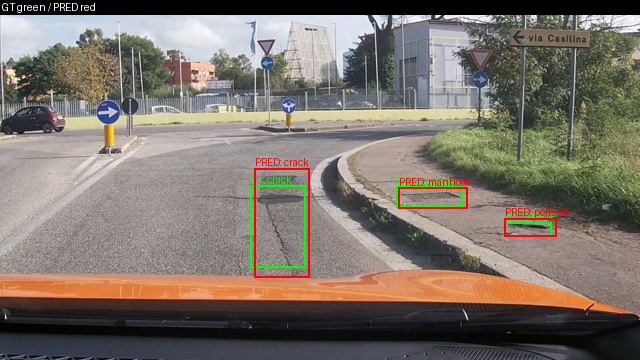

vlcsnap-2025-02-19-17h04m47s362 GT xanh, dự đoán đỏ; TP=3, FP=0, FN=0. Đúng toàn bộ box.


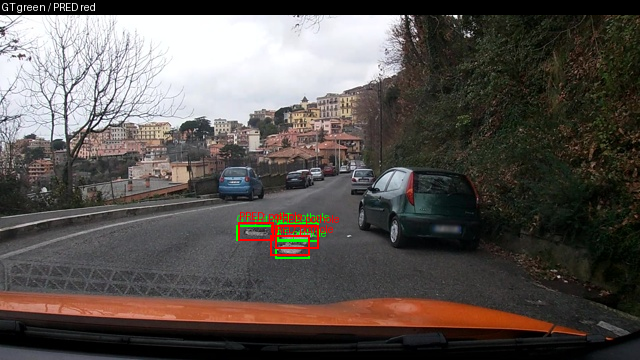

vlcsnap-00200 GT xanh, dự đoán đỏ; TP=2, FP=0, FN=0. Đúng toàn bộ box.


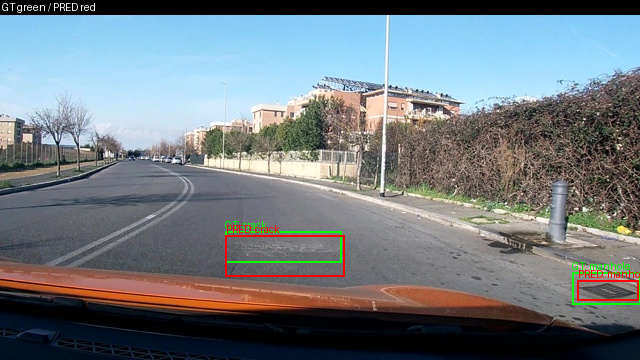

vlcsnap-2025-02-19-17h08m59s876 GT xanh, dự đoán đỏ; TP=0, FP=3, FN=5. Còn box thừa hoặc bỏ sót.


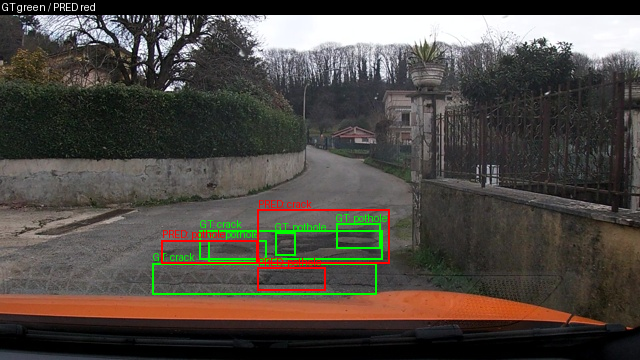

vlcsnap-2025-02-18-23h24m34s484 GT xanh, dự đoán đỏ; TP=0, FP=3, FN=4. Còn box thừa hoặc bỏ sót.


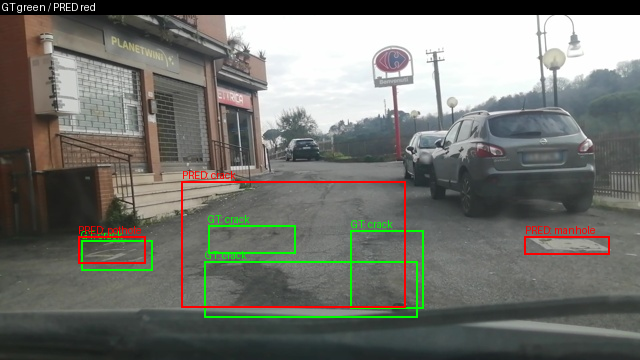

vlcsnap-2025-02-18-23h24m36s429 GT xanh, dự đoán đỏ; TP=0, FP=2, FN=5. Còn box thừa hoặc bỏ sót.


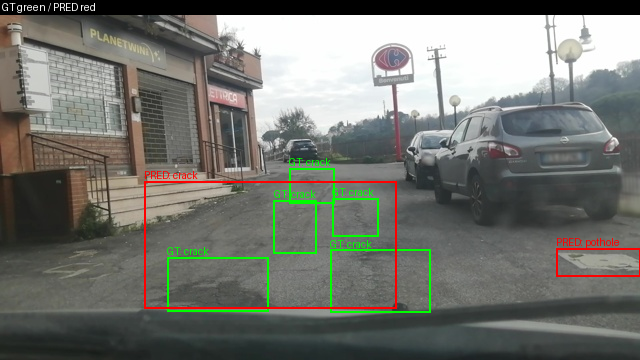

{'dataset_version': 'd10-21e4070301', 'split': 'test', 'prediction': 'work/predictions/e3_r300_v1_test.jsonl', 'description': 'Cùng prediction E3, không suy luận/train lại; cố ý chấm sai thang để phân tích lỗi.', 'correct_norm1000_f1': 0.4335154826958106, 'wrong_pixel_f1': 0.0, 'parse_valid_rate': 0.9935691318327974}


In [18]:
try:
    from IPython.display import display, Image
except ImportError:
    # Terminal CPU check: verify files without installing notebook dependencies.
    from PIL import Image as PILImage
    def Image(filename):
        with PILImage.open(filename) as image:
            image.verify()
        return filename
    def display(value):
        print('Image verified:', value)
manifest = json.loads((ROOT / 'report/analysis/figure_manifest.json').read_text(encoding='utf-8'))
for example in manifest['examples']:
    print(example['image_id'], example['caption'])
    display(Image(filename=str(ROOT / example['figure'])))
coord = json.loads((ROOT / 'report/analysis/coord_scale_check.json').read_text(encoding='utf-8'))
assert abs(coord['correct_norm1000_f1'] - evidence['e3']['micro']['f1']) < 1e-12
print(coord)


## 7. E4: thay đổi lượng dữ liệu
10% gồm 142 ảnh so 100% gồm 1422 ảnh; cùng300 bước/horizon 300 và setup E3. Đối chứng100% tái sử dụng prediction E3.


In [19]:
for name in ('e4_data_size_0.1', 'e4_data_size_1.0'):
    assert evidence[name]['meta']['actual_steps'] == 300
    print(name, evidence[name]['micro'])
print('F1 giảm:', evidence['e4_data_size_1.0']['micro']['f1'] - evidence['e4_data_size_0.1']['micro']['f1'])


e4_data_size_0.1 {'precision': 0.2765957446808511, 'recall': 0.3344768439108062, 'f1': 0.3027950310559006, 'tp': 195, 'fp': 510, 'fn': 388}
e4_data_size_1.0 {'precision': 0.4621359223300971, 'recall': 0.40823327615780447, 'f1': 0.4335154826958106, 'tp': 238, 'fp': 277, 'fn': 345}
F1 giảm: 0.13072045163990997


## 8. Kiểm tra và giới hạn
Một seed, AMP scale E1/E2 khác E3/E4, thiếu model revision, CI bootstrap theo ảnh. E4 v1 mất ZIP Drive nên đã train lại v2. Báo cáo200 còn trong commit 9e211e9. E5 chưa làm; không coi output trống ở notebook trình bày này là lượt suy luận mới.


In [20]:
print(json.loads((ROOT / 'report/analysis/verification.json').read_text(encoding='utf-8')))


{'date': '2026-10-16', 'original_tests_command': 'python -m pytest -q', 'original_tests': {'passed': 67, 'skipped': 1, 'failed': 1, 'failure': 'tests/test_configs_and_docs.py::test_report_template_has_student_markers_and_ten_questions', 'reason': 'Test requires the unfilled REPORT marker; check_submission requires the completed report without that marker. Original tests were not edited.'}, 'submission_checker_command': 'python -X utf8 scripts/check_submission.py', 'submission_checker': {'fail': 0, 'warn': 0}, 'dataset_version': 'd10-21e4070301', 'actual_training_steps': {'E1': 300, 'E2': 300, 'E3': 300, 'E4_0.1': 300, 'E4_1.0': 300}, 'important_limitation': 'One seed; different AMP scales between E1/E2 and E3/E4; null model revision. Figures and coordinate trap updated from real E3 step300 predictions.', 'source': 'extended300_results (1).zip and lab_day10_continue300_(2).ipynb supplied by student', 'e4_recovery': 'v1 Drive archive read as zero bytes in next session; v2 retrained from 